In [166]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib
import numpy as np
import scipy.optimize
import odrpack

plt.rcParams["figure.dpi"] = 150
plt.rcParams["text.usetex"] = True
plt.rcParams["font.size"] = 12


# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'Computer Modern'


plt.rcParams['font.family'] = 'serif' # or 'sans-serif' or 'monospace'
plt.rcParams['font.serif'] = 'cmr10'
plt.rcParams['font.sans-serif'] = 'cmss10'
plt.rcParams['font.monospace'] = 'cmtt10'
plt.rcParams["axes.formatter.use_mathtext"] = True # to fix the minus signs
%config InlineBackend.figure_format = 'retina'
plt.rcParams['axes.grid'] = True

In [167]:
def string_to_float_list(data_string: str):
    return np.array([float(x) for x in data_string.split()])

In [168]:
wavelength = 650e-9
wavevector = 2*np.pi / wavelength

gas_width = 17e-3

kpa_per_atm = 101.325

In [169]:
trial_2_pressures = string_to_float_list("""
0
12
21
28
36
44
52
70
""")

trial_2_intensities = string_to_float_list("""10.243 
23.630  
32.838  
30.861 
22.697 
10.004
16.500 
16.379
""")

trial_pressures = np.array([trial_2_pressures])
trial_intensities = np.array([trial_2_intensities])

In [170]:
def fit_curve(P, I0, k, phi_glass):
    n = 1 + k * P
    return I0  * np.cos((n * wavevector * gas_width + phi_glass) / 2)**2

1.0003013472636137


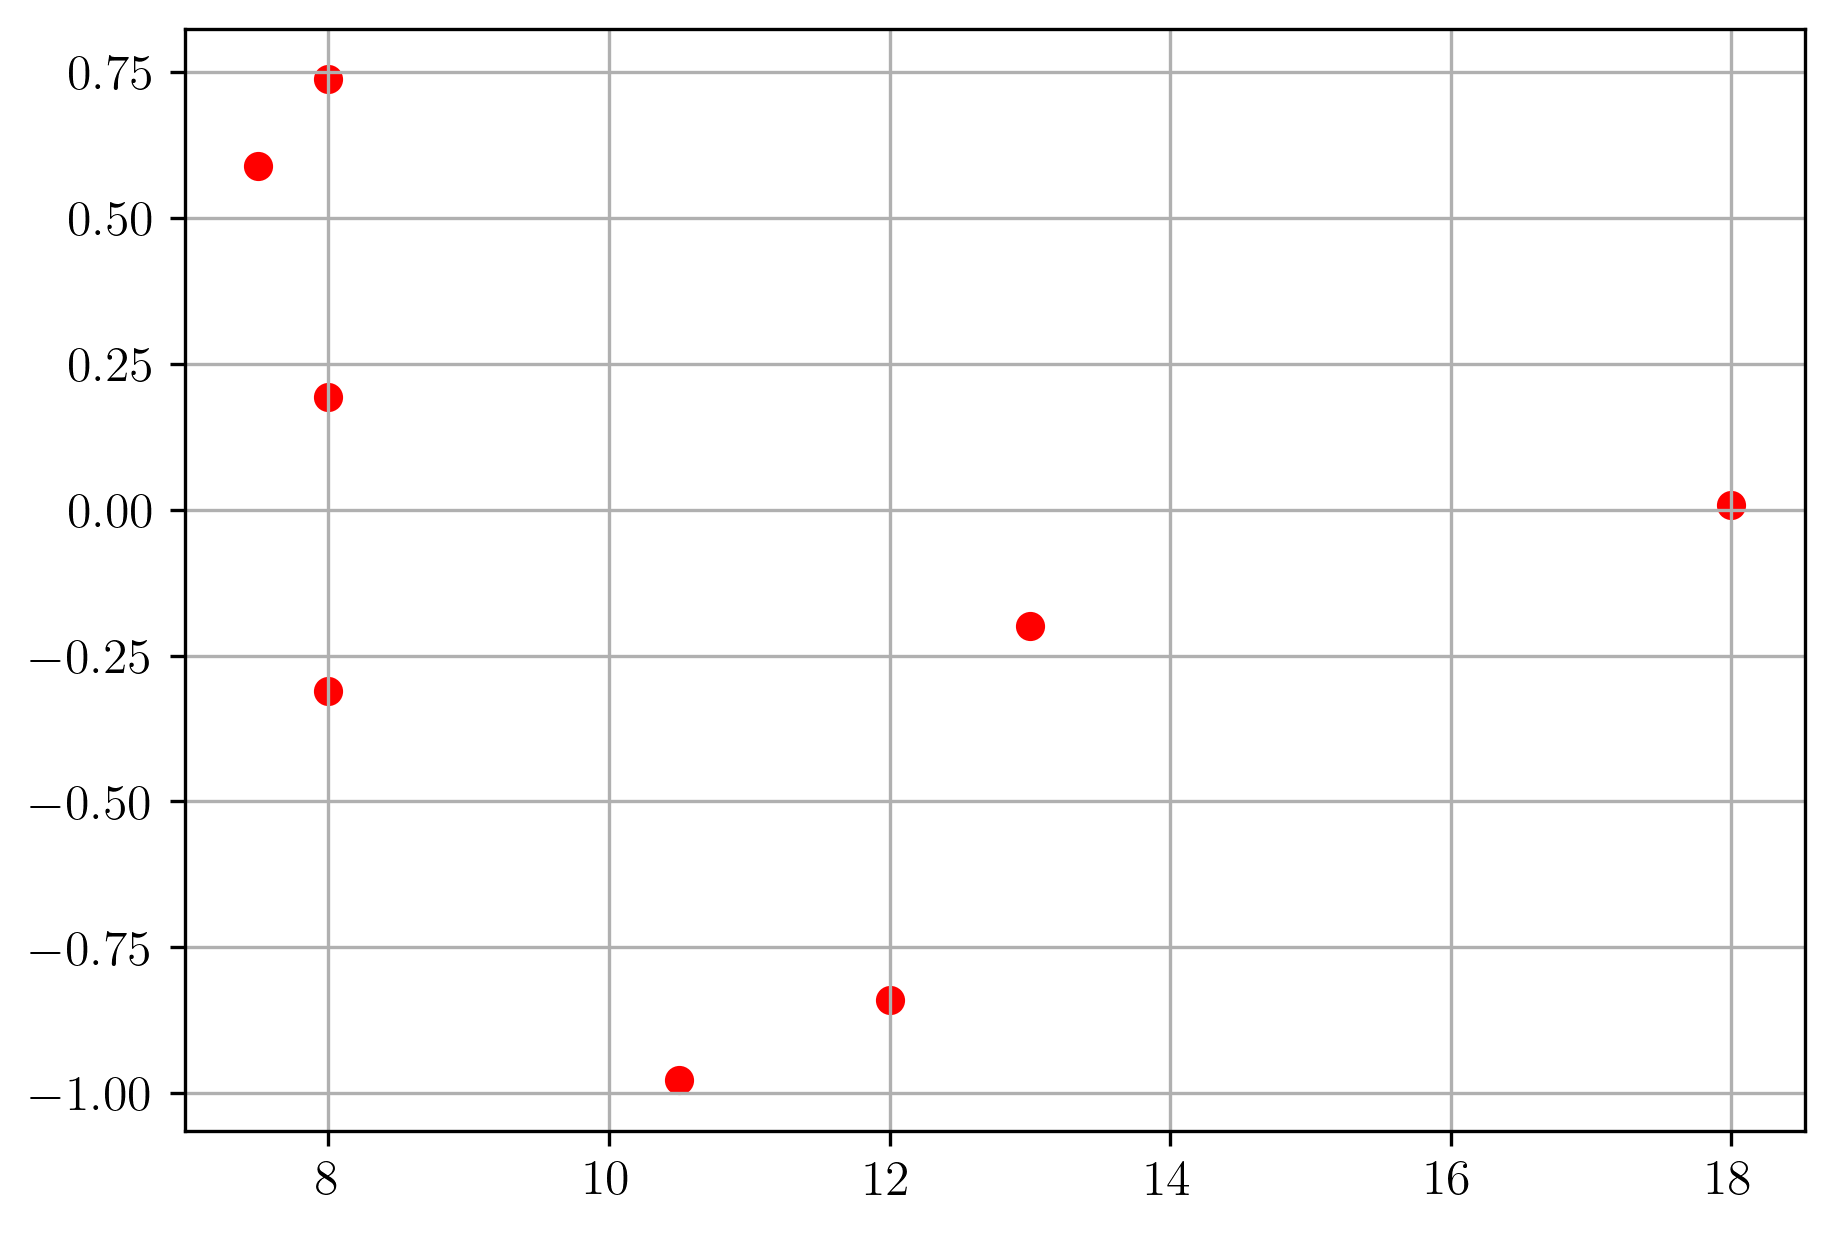

In [171]:
for i in range(len(trial_pressures)):
    pressure = trial_pressures[i]
    intensity = trial_intensities[i]

    popt, pcov = scipy.optimize.curve_fit(fit_curve, pressure, intensity, p0 = (30, (1.0003 - 1) / kpa_per_atm, 0), bounds=([0, 0, -np.pi], [np.inf, 5e-6, np.pi]))
    I0, k, phi_glass = popt[0], popt[1], popt[2]
    n = 1 + k * kpa_per_atm
    print(n)

    linearized_intensity = 2 * np.arccos(np.sqrt(intensity / max(intensity)))


    fig, ax = plt.subplots(1, figsize=(6, 4), layout='constrained')

    xvals = np.linspace(0, 80, 1000)
    #ax.plot(xvals, fit_curve(xvals, *popt))

    #ax.scatter(pressure, intensity)

    #ax.scatter(pressure, linearized_intensity)

    ax.scatter(np.gradient(pressure), np.gradient(linearized_intensity), color = 'red')